In [ ]:
#What factors are most realted to the popularty of drakes diffrent music 
#Are his singl tracks or tracks featureing more popular 
#What atribues of the song most popular 
#Is there any trend over the years with his musuic. Gone from more to less energetic. 

In [286]:
import requests
import re
import pandas as pd 
import numpy as np 
import seaborn as sb 
import datetime
from matplotlib import pyplot as plt

In [287]:
#establishing a clientID and clientSecret to access the Spotify API 
clientID = "95b3885a0ef74d5aa117ed6cee551f31"
clientSecret = "8bef6a0ab4b244bcb024eae23dc12f96"
rootURL = "https://api.spotify.com/"
#drakeID: 3TVXtAsR1Inumwj472S9r4

grantType = 'client_credentials'

bodyParams = {'grant_type' : grantType}

url='https://accounts.spotify.com/api/token'

response=requests.post(url, data=bodyParams, auth = (clientID, clientSecret)).json()

headers = {"Authorization": "Bearer "+response["access_token"]} 

In [288]:
drakeInfo = requests.get(rootURL+"v1/artists/3TVXtAsR1Inumwj472S9r4/albums",headers=headers).json()

#created empty lists and dictionaries to store variables later in the code 
albumIDList = []
trackIDList = []
drakeAlbums = {}

#looped through the request to get the album id of each of his albums and stored the album ids in an empty list 
for artist in drakeInfo["items"]:
    albumID = artist["id"]
    albumIDList.append(albumID)

#delete all the albums that are newer than 2021 
#https://stackoverflow.com/questions/627435/how-to-remove-an-element-from-a-list-by-index
del albumIDList[0]
del albumIDList[0]
del albumIDList[0]
del albumIDList[0]
#delete irrelevant albums(like instrumentals)
del albumIDList[-1]
del albumIDList[-1]
del albumIDList[-1]
del albumIDList[9]

#I created one big string of all the album ids and used a comma to join each of them so that I could do a request for 
#several albums
#https://stackoverflow.com/questions/5618878/how-to-convert-list-to-string
albumString = ','.join(albumIDList)
severalAlbums = requests.get(rootURL+"v1/albums?ids="+albumString,headers=headers).json()

#had all the keys of the empty dictionary equal to name, year, popularity, and album id. 
drakeAlbums["albumName"] = []
drakeAlbums["albumReleaseYear"] = []
drakeAlbums["albumPopularity"] = []
drakeAlbums["albumID"] = []

#looped through the several albums request to get the name, year, popularity, and album id of each of his albums and 
#appened them all to the dictionary 
for album in severalAlbums["albums"]:
    albumName = album["name"]
    albumReleaseDate = album["release_date"]
    albumPopularity = album["popularity"]
    spotifyAlbumID = album["id"]
    drakeAlbums["albumName"].append(albumName)
    drakeAlbums["albumReleaseYear"].append(albumReleaseDate)
    drakeAlbums["albumPopularity"].append(albumPopularity)
    drakeAlbums["albumID"].append(spotifyAlbumID)
    
#created a dataframe with the dictionarty and sorted the values from greatest to least using album popularity. 
#this data frame shows all of Drakes albums form his first one to the year 2021 and orders each one by popularity, 
#from most to least
drakeAlbumsDF = pd.DataFrame.from_dict(drakeAlbums).sort_values("albumPopularity", ascending=False)
#https://stackoverflow.com/questions/25146121/extracting-just-month-and-year-separately-from-pandas-datetime-column
#because the albumReleaseYear column was originally displaying the whole date and I wanted just the year, I used 
#.apply and lambda to change it to just the year and release.
drakeAlbumsDF["albumReleaseYear"] = drakeAlbumsDF["albumReleaseYear"].apply(lambda x: pd.to_datetime(x).year)
drakeAlbumsDF


,albumName,albumReleaseYear,albumPopularity,albumID
5,Views,2016,81,40GMAhriYJRO1rsY4YdrZb
0,Certified Lover Boy,2021,80,3SpBlxme9WbeQdI9kx7KAV
9,Take Care (Deluxe),2011,80,6X1x82kppWZmDzlXXK3y3q
3,Scorpion,2018,79,1ATL5GLyefJaxhQzSPVrLX
4,More Life,2017,79,1lXY618HWkwYKJWBRYR4MK
1,Dark Lane Demo Tapes,2020,75,6OQ9gBfg5EXeNAEwGSs6jK
2,Care Package,2019,71,7dqpveMVcWgbzqYrOdkFTD
7,If You're Reading This It's Too Late,2015,71,0ptlfJfwGTy0Yvrk14JK1I
11,So Far Gone,2009,70,1LShhEEKRT5MNPcO7jtYHh
10,Thank Me Later,2010,68,6jlrjFR9mJV3jd1IPSplXU


/Users/nirajachapagain/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


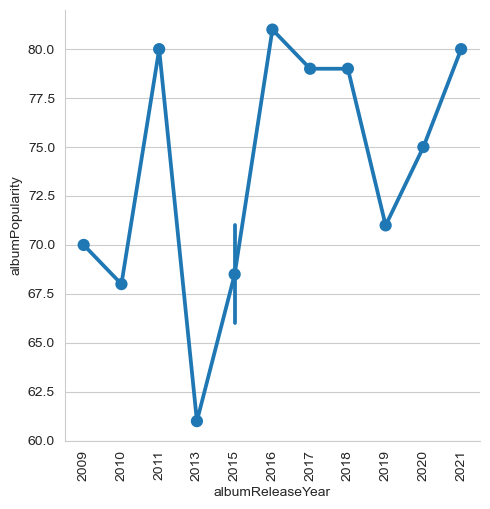

In [289]:
#This catplot shows the progression of Drakes album popularity through the years since the start of his career up until 
#2021. Although there are points where the popularity soars up or goes way down, you can see that his popularity has 
#stayed pretty consistent throughout the years usally hovering around the 70s range. 
sb.catplot(x="albumReleaseYear",y="albumPopularity",data=drakeAlbumsDF,kind="point").set_xticklabels(rotation=90)

In [330]:
#Top 2 

#Certified Lover Boy data frame
#created an empty dictionary with track name, dancibility, energy, release rate, album name, and artist name as keys.
clbTrackIDList = []
clbtopTracksFeatures = {}
clbtopTracksFeatures["trackName"] = []
clbtopTracksFeatures["popularity"] = []
clbtopTracksFeatures["danceability"] = []
clbtopTracksFeatures["energy"] = []
clbtopTracksFeatures["releaseYear"] = []
clbtopTracksFeatures["albumName"] = []
clbtopTracksFeatures["artistName"] = []

#got the album id from the above data frame and used that to make a request for all the tracks in that album
certifiedLoverBoy = drakeAlbumsDF["albumID"][0]
clbTracks = requests.get(rootURL+"v1/albums/"+certifiedLoverBoy+"/tracks",headers=headers).json()

#looped through the request of the tracks and first created an empty list within the loop to group all of the artists
#for each track. Then I appened the ids of the tracks into an empty list to use for later and also appened the names
#of the tracks into the dictionary. Then I created a nested loop to get the artists for each of the tracks and appened 
#the neames into the empty list created before. Then since some had multiple artists, I created a string and used a comma 
#to join the artist names and appened that string into the dictionary. 
for items in clbTracks["items"]:
    clbtrackArtists = []
    clbNames = items["name"]
    clbIDs = items["id"]
    clbTrackIDList.append(clbIDs)
    clbtopTracksFeatures["trackName"].append(clbNames)
    for artists in items["artists"]:
        clbartistNames = artists["name"]
        clbtrackArtists.append(clbartistNames)
    clbArtistString = ', '.join(clbtrackArtists)
    clbtopTracksFeatures["artistName"].append(clbArtistString)
    
#I then used that method again to join the track ids using a comma so that I could make a request for several tracks and
#also their audio feartures features 
clbTrackString = ','.join(clbTrackIDList)

#I made a request for several tracks using the string above and looped through the request to get the popularity of each of 
#the tracks and append that into the data frame
clbTracksPop = requests.get(rootURL+"v1/tracks?ids="+clbTrackString,headers=headers).json()
for details in clbTracksPop["tracks"]:
    popularity = details["popularity"]
    clbtopTracksFeatures["popularity"].append(popularity)

#made a request for the audio features for each of the tracks
clbTracksAudio = requests.get(rootURL+"v1/audio-features?ids="+clbTrackString,headers=headers).json()

#I looped through the audio features request to get the dancibility and energy of each track in the album and appened it 
#to the dictionary
for features in clbTracksAudio["audio_features"]:
    danceability = features["danceability"]
    energy = features["energy"]
    clbtopTracksFeatures["danceability"].append(danceability)
    clbtopTracksFeatures["energy"].append(energy)

#since I already had the year the tracks were released from the previous data frame, I used that and made it equal to the 
#releaseYear column and I did the same with the album name.
clbYear = str(drakeAlbumsDF["albumReleaseYear"][0])
clbtopTracksFeatures["releaseYear"] = clbYear
clbtopTracksFeatures["albumName"] = drakeAlbumsDF["albumName"][0]
# clbtopTracksFeatures["top/bottom"] = "top"

#I then turned the dictionary into a data frame using pd.DataFrame.from_dict. Lastly I created another column is 
#feature and used ,apply and lambda to check if there was a comma within the artistName column and if there was 
#I knew that it was a feature and if not then it was a single. 
clbTracksDF = pd.DataFrame.from_dict(clbtopTracksFeatures)
clbTracksDF["isFeature"] = clbTracksDF["artistName"].apply(lambda x: "Feature" if re.findall("\w*,\w*",x) else "Single")


#I used the same steps as above for the second most popular album which was Views 
#Views album data frame
viewsTrackIDList = []
viewstopTracksFeatures = {}
viewstopTracksFeatures["trackName"] = []
viewstopTracksFeatures["popularity"] = []
viewstopTracksFeatures["danceability"] = []
viewstopTracksFeatures["energy"] = []
viewstopTracksFeatures["releaseYear"] = []
viewstopTracksFeatures["albumName"] = []
viewstopTracksFeatures["artistName"] = []

views = drakeAlbumsDF["albumID"][5]
viewsTracks = requests.get(rootURL+"v1/albums/"+views+"/tracks",headers=headers).json()

for items in viewsTracks["items"]:
    viewstrackArtists = []
    viewsNames = items["name"]
    viewsIDs = items["id"]
    viewsTrackIDList.append(viewsIDs)
    viewstopTracksFeatures["trackName"].append(viewsNames)
    for artists in items["artists"]:
        viewsartistNames = artists["name"]
        viewstrackArtists.append(viewsartistNames)
    viewsArtistString = ', '.join(viewstrackArtists)
    viewstopTracksFeatures["artistName"].append(viewsArtistString)
    

    
viewsTrackString = ','.join(viewsTrackIDList)
viewsTracksPop = requests.get(rootURL+"v1/tracks?ids="+viewsTrackString,headers=headers).json()
for details in viewsTracksPop["tracks"]:
    popularity = details["popularity"]
    viewstopTracksFeatures["popularity"].append(popularity)

viewsTracksAudio = requests.get(rootURL+"v1/audio-features?ids="+viewsTrackString,headers=headers).json()


for features in viewsTracksAudio["audio_features"]:
    danceability = features["danceability"]
    energy = features["energy"]
    viewstopTracksFeatures["danceability"].append(danceability)
    viewstopTracksFeatures["energy"].append(energy)
    
viewsYear = str(drakeAlbumsDF["albumReleaseYear"][5])
viewstopTracksFeatures["releaseYear"] = viewsYear
viewstopTracksFeatures["albumName"] = drakeAlbumsDF["albumName"][5]
# viewstopTracksFeatures["top/bottom"] = "top"

viewsTracksDF = pd.DataFrame.from_dict(viewstopTracksFeatures)
viewsTracksDF["isFeature"] = viewsTracksDF["artistName"].apply(lambda x: "Feature" if re.findall("\w*,\w*",x) else "Single")

In [331]:
#Bottom 2 
#I used the same steps as above but now for the bottom 2 albums and their tracks 
#PSA: I do understand that I could have done this easier and without as much code using a function and passing in the 
#albums but, since I was already done with the code for the top 2 and ended up adding the bottom 2 I just decided to keep 
#it how it was

#What A Time To Be Alive data frame
watTrackIDList = []
wattopTracksFeatures = {}
wattopTracksFeatures["trackName"] = []
wattopTracksFeatures["popularity"] = []
wattopTracksFeatures["danceability"] = []
wattopTracksFeatures["energy"] = []
wattopTracksFeatures["releaseYear"] = []
wattopTracksFeatures["albumName"] = []
wattopTracksFeatures["artistName"] = []

whatATime = drakeAlbumsDF["albumID"][6]
watTracks = requests.get(rootURL+"v1/albums/"+whatATime+"/tracks",headers=headers).json()


for items in watTracks["items"]:
    wattrackArtists = []
    watNames = items["name"]
    watIDs = items["id"]
    watTrackIDList.append(watIDs)
    wattopTracksFeatures["trackName"].append(watNames)
    for artists in items["artists"]:
        watartistNames = artists["name"]
        wattrackArtists.append(watartistNames)
    watArtistString = ', '.join(wattrackArtists)
    wattopTracksFeatures["artistName"].append(watArtistString)
    
    
watTrackString = ','.join(watTrackIDList)

watTracksPop = requests.get(rootURL+"v1/tracks?ids="+watTrackString,headers=headers).json()
for details in watTracksPop["tracks"]:
    popularity = details["popularity"]
    wattopTracksFeatures["popularity"].append(popularity)


watTracksAudio = requests.get(rootURL+"v1/audio-features?ids="+watTrackString,headers=headers).json()


for features in watTracksAudio["audio_features"]:
    danceability = features["danceability"]
    energy = features["energy"]
    wattopTracksFeatures["danceability"].append(danceability)
    wattopTracksFeatures["energy"].append(energy)


watYear = str(drakeAlbumsDF["albumReleaseYear"][6])
wattopTracksFeatures["releaseYear"] = watYear
wattopTracksFeatures["albumName"] = drakeAlbumsDF["albumName"][6]
# wattopTracksFeatures["top/bottom"] = "bottom"


watTracksDF = pd.DataFrame.from_dict(wattopTracksFeatures)
watTracksDF["isFeature"] = watTracksDF["artistName"].apply(lambda x: "Feature" if re.findall("\w*,\w*",x) else "Single")


#Nothing was the same 
nwtsTrackIDList = []
nwtstopTracksFeatures = {}
nwtstopTracksFeatures["trackName"] = []
nwtstopTracksFeatures["popularity"] = []
nwtstopTracksFeatures["danceability"] = []
nwtstopTracksFeatures["energy"] = []
nwtstopTracksFeatures["releaseYear"] = []
nwtstopTracksFeatures["albumName"] = []
nwtstopTracksFeatures["artistName"] = []

nwts = drakeAlbumsDF["albumID"][8]
nwtsTracks = requests.get(rootURL+"v1/albums/"+nwts+"/tracks",headers=headers).json()

for items in nwtsTracks["items"]:
    nwtstrackArtists = []
    nwtsNames = items["name"]
    nwtsIDs = items["id"]
    nwtsTrackIDList.append(nwtsIDs)
    nwtstopTracksFeatures["trackName"].append(nwtsNames)
    for artists in items["artists"]:
        nwtsartistNames = artists["name"]
        nwtstrackArtists.append(nwtsartistNames)
    nwtsArtistString = ', '.join(nwtstrackArtists)
    nwtstopTracksFeatures["artistName"].append(nwtsArtistString)
    

    
nwtsTrackString = ','.join(nwtsTrackIDList)
nwtsTracksPop = requests.get(rootURL+"v1/tracks?ids="+nwtsTrackString,headers=headers).json()
for details in nwtsTracksPop["tracks"]:
    popularity = details["popularity"]
    nwtstopTracksFeatures["popularity"].append(popularity)

nwtsTracksAudio = requests.get(rootURL+"v1/audio-features?ids="+nwtsTrackString,headers=headers).json()


for features in nwtsTracksAudio["audio_features"]:
    danceability = features["danceability"]
    energy = features["energy"]
    nwtstopTracksFeatures["danceability"].append(danceability)
    nwtstopTracksFeatures["energy"].append(energy)
    
nwtsYear = str(drakeAlbumsDF["albumReleaseYear"][8])
nwtstopTracksFeatures["releaseYear"] = nwtsYear
nwtstopTracksFeatures["albumName"] = drakeAlbumsDF["albumName"][8]
# nwtstopTracksFeatures["top/bottom"] = "bottom"

nwtsTracksDF = pd.DataFrame.from_dict(nwtstopTracksFeatures)
nwtsTracksDF["isFeature"] = nwtsTracksDF["artistName"].apply(lambda x: "Feature" if re.findall("\w*,\w*",x) else "Single")

In [332]:
viewsTracksDF['top/bottom'] = 'top'
clbTracksDF['top/bottom'] = 'top'
watTracksDF['top/bottom'] = 'bottom'
nwtsTracksDF['top/bottom'] = 'bottom'

In [336]:
#Combined data frame into one big data drame so its easier to see the similarities and diffrences between the 4 albums
#the top 2 and the bottom 2 
#https://pandas.pydata.org/docs/user_guide/merging.html
frames = [viewsTracksDF,clbTracksDF,watTracksDF,nwtsTracksDF]
drakeTopTracksDF = pd.concat(frames)
#https://www.geeksforgeeks.org/pandas-how-to-shuffle-a-dataframe-rows/
#I realized that when merging the data frames it made order of the combined data frame the same order as when it was 
#added in so it was the top 2 and the bottom 2. Becaues of that the first 40 rows for the top/bottom column was "top" and
#the last 40 rows was "bottom". Because it was in that order, it created issues with my visualization below where it was 
#only showing the dots for the "top" values. Thus I figured by scattering it, would make it more dispersed. 

drakeTopTracksDF.head(60)

,trackName,popularity,danceability,energy,releaseYear,albumName,artistName,isFeature,top/bottom
0,Keep The Family Close,60,0.378,0.566,2016,Views,Drake,Single,top
1,9,63,0.680,0.712,2016,Views,Drake,Single,top
2,U With Me?,61,0.429,0.430,2016,Views,Drake,Single,top
3,Feel No Ways,75,0.582,0.677,2016,Views,Drake,Single,top
4,Hype,61,0.787,0.635,2016,Views,Drake,Single,top
5,Weston Road Flows,61,0.623,0.740,2016,Views,Drake,Single,top
6,Redemption,66,0.694,0.314,2016,Views,Drake,Single,top
7,With You,63,0.878,0.406,2016,Views,"Drake, PARTYNEXTDOOR",Feature,top
8,Faithful,57,0.536,0.449,2016,Views,"Drake, dvsn, Pimp C",Feature,top
9,Still Here,65,0.834,0.433,2016,Views,Drake,Single,top


<Axes: xlabel='danceability', ylabel='energy'>

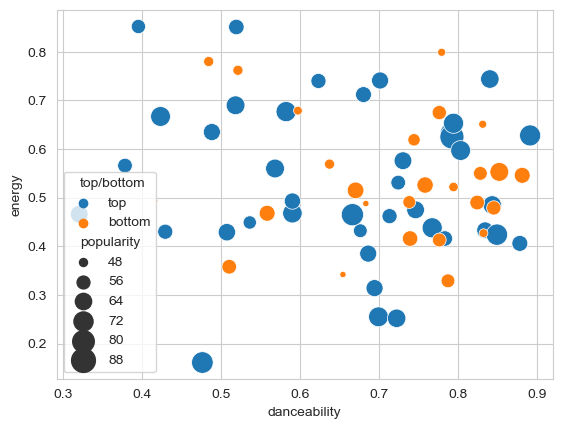

In [343]:
#Visualization showing how the tracks of his top 2 albums and his bottom 2 performed whether its looking at popularitty
#or the levels of dancibility and energy of each of the tracks. 

#Overall, you can see that many of Drakes tracks, score towards the higher range of dancibility and the energy tends
#to hover around 0.4 to 0.7. 

#Danceability describes how suitable a track is for dancing
#Energy is a measure from 0.0 to 1.0 and represents a perceptual measure of intensity and activity


#When looking at the comparison between the top and the bottom, you can tell that the dots for the top are more dispersed
#where as the dots for the bottom are more cluttered toward the right end of the dancebility scale. You can also see that 
#the top ones score much higher in popularity because the circles are larger. Similar to the findings from the top and bottom
#you can see that the features tend to be on the higher spectrum of danceibility but the singels are more spread out. 

#Analyzing this scatter plot, you can come to the conclusion that there is no apparent correlation between dancibility score 
#and popularity of a track. You can tell especially with the the tracks from the top album that, even when a track scores 
#lower or even the lowest on dancibility, being all the way to the left of the plot, it still has a similar popularity 
#score as a track that is all the way on the left. With relation to energy, I think the points tend to fall mostly around 
#the middle so I dont think there is much to be analyzed from that standpoint. 


sb.scatterplot(data=drakeTopTracksDF, x="danceability",y="energy",hue="top/bottom",size="popularity",sizes=(1, 300))


In [344]:
#created a dictionary to add the views for each of the artists 
artistInfo = {}

drakeDF = pd.read_csv("drake_data.csv")
#Makes sure that none of the values in the track_views column is null
notNullDF = drakeDF[drakeDF["track_views"].notnull()]

#https://www.digitalocean.com/community/tutorials/python-remove-character-from-string
#https://www.geeksforgeeks.org/using-apply-in-pandas-lambda-functions-with-multiple-if-statements/
#Change the values in the track_views column to a flost by using .apply and lambda. I replaced the K with an
#emty string and multiplied that value by 1000 to get it in thousands or replaced M with an empty string and multiplied it
#by 1 million to get it in millions. 
notNullDF["track_views"] = notNullDF["track_views"].apply(lambda x: float(x.replace("K",""))*1000 if "K" in x else float(x.replace("M",""))*1000000 if "M" in x else None)

# https://cheatography.com/davechild/cheat-sheets/regular-expressions/
#to find the artist that is featured, I used .apply and lambda and used re.find all. The \ folowed by the ( tells it 
#to escape the parenthesis to not include it in the artist name, the Ft. following that makes sure to only match those 
#characters, the \s makes sure thre is a white space, then after that the ([^)] tells it to match any character except 
#the closing parenthesis and finally the \) after that also tells it to escape the ending parenthesis. 
artist = notNullDF["lyrics_title"].apply(lambda x: re.findall("\(Ft.\s([^)]*)\)",x)[0] if re.findall("\(Ft.\s([^)]*)\)",x) else None )
#I then created a new row called features on the data frame and added the artists on there
notNullDF["feature"] = artist
#Since some have multiple artists, to get only the primary feature I used . apply and lambda to split the string using
#& as a delimiter and I only used the first index as the primary feature. 
notNullDF["primary feature"] = notNullDF["feature"].apply(lambda x: x.split("&")[0] if x is not None else None)
# https://stackoverflow.com/questions/8270092/remove-all-whitespace-in-a-string
#Some of the string has random white spaces so I used .str.strip() to remove the whitespace. 
notNullDF["primary feature"] = notNullDF["primary feature"].str.strip()
trackCounts = notNullDF["primary feature"].value_counts()

#https://note.nkmk.me/en/python-pandas-dataframe-for-iteration/
#I itterated through the rows of the data frame, made primary eyal to the primary feature row and views euqal to the 
#track_views roe. Then if the primary artist was already in the the dictionary, I just added the views to that original
#value. If it wasnt already there, I just made it equal to the views. 
for index, row in notNullDF.iterrows():
    primary = row["primary feature"]
    views = row["track_views"]
    if primary in artistInfo:
        artistInfo[primary] += views
    else: 
        artistInfo[primary] = views

#https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.from_dict.html
# I changed the artist views dictionary into a datafram and made the column to views and the index equal to the primary artist 
#I then reset the index to drop the current index to format it and make it look like how I want to. Then I sort the values 
#from greatest to least in oreder of views. 
infoDF = pd.DataFrame.from_dict(artistInfo,orient="index")
infoDF.columns = ["views"]
infoDF["primary"] = infoDF.index

#https://stackoverflow.com/questions/24216425/adding-a-new-pandas-column-with-mapped-value-from-a-dictionary
#I added a new column to the data frame by using .map and also using the value counts of the total track features that 
#each artist has had. Then, to make sure I could do division for the views per track, I used .apply and lambda to turn 
#those values into a float. 
infoDF["trackCounts"] = infoDF["primary"].map(trackCounts)
infoDF["trackCounts"] = infoDF["trackCounts"].apply(lambda x: float(x))

#I then created a new column called views per tack by diving the views by the track counts and that gave the views per 
#track for each of the feature artists. The number came out in scientific notation so I used .format to change the format 
#to standard. And to makre sure that I could sort the values I also turned the views per track into floats. 
infoDF["viewsPerTrack"] = infoDF["views"] / infoDF["trackCounts"]
infoDF["viewsPerTrack"] = infoDF["viewsPerTrack"].apply(lambda x: '{:.0f}'.format(x))
infoDF["viewsPerTrack"] = infoDF["viewsPerTrack"].apply(lambda x: float(x))

#I made sure that the primary artist didnt equal Drake or null. I then sorted those values again based on views 
#from greatest to least. I also only inluced the top 20 from the data frame becasue I didnt want to display all 
#of the feature artists
notDrakeDF = newInfoDF[(newInfoDF["primary"] != 'Drake') & (newInfoDF["primary"].notnull())]
notDrakeDF = notDrakeDF.sort_values("viewsPerTrack", ascending=False).head(20)
notDrakeDF

/var/folders/y_/yq94_nc17ln4xh4yhh19j1mm0000gn/T/ipykernel_25353/3685303285.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  notNullDF["track_views"] = notNullDF["track_views"].apply(lambda x: float(x.replace("K",""))*1000 if "K" in x else float(x.replace("M",""))*1000000 if "M" in x else None)
/var/folders/y_/yq94_nc17ln4xh4yhh19j1mm0000gn/T/ipykernel_25353/3685303285.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  notNullDF["feature"] = artist
/var/folders/y_/yq94_nc17ln4xh4yhh19j1mm0000gn/T/ipyk

,views,primary,trackCounts,viewsPerTrack
26,5800000.0,Kyla,1.0,5800000.0
32,5400000.0,Majid Jordan,1.0,5400000.0
21,5000000.0,2 Chainz,2.0,2500000.0
12,2200000.0,James Fauntleroy,1.0,2200000.0
27,4300000.0,Rihanna,2.0,2150000.0
20,2000000.0,Quavo,1.0,2000000.0
31,3613100.0,Jhené Aiko,2.0,1806550.0
14,4615400.0,JAY-Z,3.0,1538467.0
30,1400000.0,Travis Scott,1.0,1400000.0
9,4053000.0,Sampha,3.0,1351000.0


/Users/nirajachapagain/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


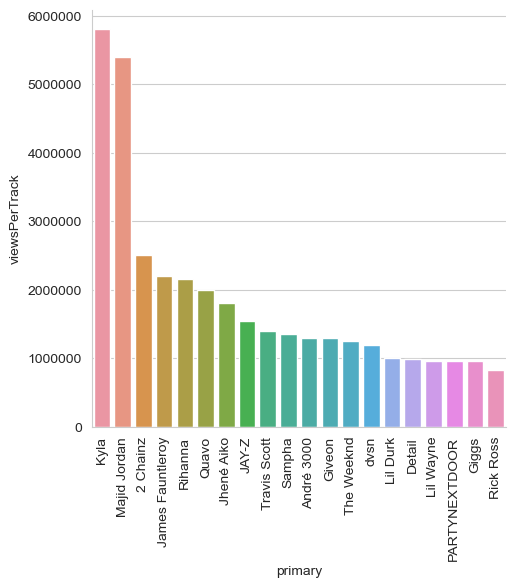

In [345]:
#I used a catplot because the data points were based on categorical data which was the artist. I made the x-axis the 
#different artists and the y-axis the total views per track of these artists and only included 20 artists. Some artists had very high views but I 
#also noticed that those artists also had more track features than the rest so to make it more realistic I decided to 
#do views per track by dividing the total views by the total number of tracks each artist had It is in order from 
#greatest views to least views. My visualization was first outputing in scientific notation so I used plt.ticklabel_format 
#to make the values of the the y-axis the original values presented in teh data frame.  
sb.set_style(style="whitegrid")
sb.catplot(x="primary",y="viewsPerTrack",data=notDrakeDF,kind="bar").set_xticklabels(rotation=90)
#https://www.tutorialspoint.com/how-to-repress-scientific-notation-in-factorplot-y-axis-in-seaborn-matplotlib
plt.ticklabel_format(style='plain', axis='y')

#This visualization shows the most popular artists from the features that he has done by talking into account the amount 
#of tracks that the artist has been featured in. The most popular being Kyla and the least popular being Future. At first, 
#I was only looking at the total views that each artist had the result of that was Lil Wayne having the most views surpassing 
#the rest of the artists by thousands of views. But then it made more sense to look at the views per feature that the artist 
#has done. After doing that, since Lil Wayne has had many more track features than the rest of the artists, Lil Wayne 
#ended up being one of the bottom artists with the least views per track. 

In [299]:
BillboardDF = pd.read_csv("Billboard 'The Hot 100' Songs.csv")
BillboardDF.sort_values("weeks-on-board",ascending=False)

,date,rank,song,artist,last-week,peak-rank,weeks-on-board
919,2021-09-04,20,Blinding Lights,The Weeknd,21.0,1,90
1020,2021-08-28,21,Blinding Lights,The Weeknd,18.0,1,89
1117,2021-08-21,18,Blinding Lights,The Weeknd,16.0,1,88
39148,2014-05-10,49,Radioactive,Imagine Dragons,48.0,3,87
1215,2021-08-14,16,Blinding Lights,The Weeknd,17.0,1,87
...,...,...,...,...,...,...,...
147587,1993-07-31,88,Cryin',Aerosmith,NaN,88,1
292063,1965-11-20,77,Apple Of My Eye,Roy Head And The Traits,NaN,77,1
147584,1993-07-31,85,Check Yo Self,Ice Cube Featuring Das EFX,NaN,85,1
292066,1965-11-20,80,The Sound Of Silence,Simon & Garfunkel,NaN,80,1


/var/folders/y_/yq94_nc17ln4xh4yhh19j1mm0000gn/T/ipykernel_25353/4255351931.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drakeSongsDF["isFeature"] = drakeSongsDF["artist"].apply(lambda x: "Feature" if re.findall("\w*Featuring\w*",x) else "Feature" if re.findall("\w*With\w*",x) else "Single" )
/Users/nirajachapagain/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


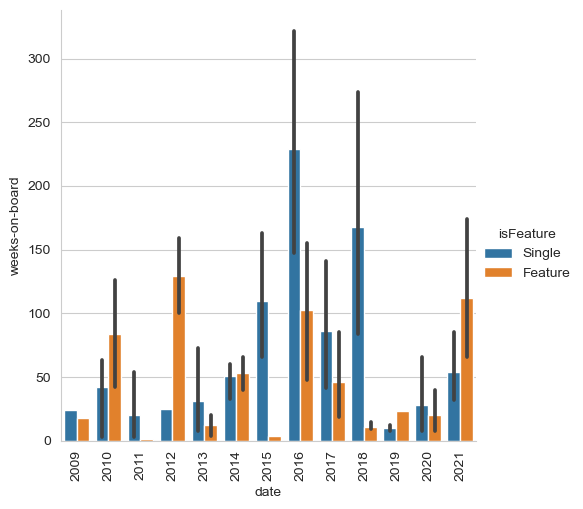

In [300]:
#applies the lambda function to each element on the artist column. The lambda function takes the artist column and checks 
#if any of the artist names is Drake. The bool returns true if matches are found and false if they arent found. Then the 
#next line selects all the rows from the data frame where the bool value is true. 

BillboardDF = pd.read_csv("Billboard 'The Hot 100' Songs.csv")
#https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#this takes the full date from the data frame and just extracts the year. 
BillboardDF["date"] = pd.to_datetime(BillboardDF["date"]).dt.year

#https://www.geeksforgeeks.org/applying-lambda-functions-to-pandas-dataframe/
#this makes sure that the song is Drakes but finding all the artists in the artist column starts with Drake
allDrakeSongs = BillboardDF["artist"].apply(lambda x: bool(re.findall("^Drake\w*",x)))
drakeSongsDF = BillboardDF[allDrakeSongs]

#using .apply and lambda to see if that song is a feature or not by checking if it had the string featuring or with in it 
#If it does then it is a feature and if it doesnt then it is a single
drakeSongsDF["isFeature"] = drakeSongsDF["artist"].apply(lambda x: "Feature" if re.findall("\w*Featuring\w*",x) else "Feature" if re.findall("\w*With\w*",x) else "Single" )
drakeSongsDF.sort_values("weeks-on-board",ascending=False)

#Then since some songs are on there multiple times, I used goupby to group the songs and used the max for each of the songs 
groupedDF = drakeSongsDF[["weeks-on-board", "song","date","isFeature"]].groupby(["song"]).max()


#https://seaborn.pydata.org/generated/seaborn.catplot.html
#Then I created a cat plot to show the sum of weeks on board for each year along with if it is a feature or a single. 
sb.catplot(x="date",y="weeks-on-board",data=groupedDF,hue="isFeature",kind="bar",estimator="sum").set_xticklabels(rotation=90)

#groupby track name and max weeks on board 
#to get just the max, compare each row, in the new groupoed data frame and match indexes with the rows